#### Import Libraries

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

#### Load and Explore Dataset
<ul>
<li>The first column (label) indicates the digit (0-9) and the remaining columns represent pixel values of the image.</li>
<li>We separate these into X (pixel values) and y (labels).</li>
</ul>

In [68]:
train_data = pd.read_csv('./Train.csv')
print(train_data.shape)

(42000, 785)


In [69]:
train_data.head(20)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [70]:
print(train_data.columns)
print(train_data.describe())

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='str', length=785)
              label   pixel0   pixel1   pixel2   pixel3   pixel4   pixel5  \
count  42000.000000  42000.0  42000.0  42000.0  42000.0  42000.0  42000.0   
mean       4.456643      0.0      0.0      0.0      0.0      0.0      0.0   
std        2.887730      0.0      0.0      0.0      0.0      0.0      0.0   
min        0.000000      0.0      0.0      0.0      0.0      0.0      0.0   
25%        2.000000      0.0      0.0      0.0      0.0      0.0      0.0   
50%        4.000000      0.0      0.0      0.0      0.0      0.0      0.0   
75%        7.000000      0.0      0.0      0.0      0.0      0.0      0.0   
max        9.000000      0.0      0.0      0.0      0.0      0.0      0.0   

        pixel6  

In [71]:
X = train_data.iloc[:, 1:]
Y = train_data.label
print(X.shape)
print(Y.shape)

(42000, 784)
(42000,)


#### Data Preprocessing
<ul>
<li>First we ensure X is in the correct format (Pandas DataFrame).</li>
<li>Then we convert all pixel values to numeric format and replace any missing values with 0.</li>
<li>Next we normalize the pixel values to the range [0, 1] by dividing them by 255.0. This helps the model learn faster.</li>
<li>Finally we reshape the data to include a channel dimension making it compatible with neural networks.</li>
</ul>

In [72]:
if not isinstance(X, pd.DataFrame):
    X = pd.DataFrame(X)
print(X.shape)
X = X.apply(pd.to_numeric, errors='coerce')
print(X.shape)
X = X.fillna(0)
print(X.values)
X = X.values / 255.0
print(X.shape)
X = X.reshape(-1, 28, 28, 1)
print(X.shape)

(42000, 784)
(42000, 784)
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(42000, 784)
(42000, 28, 28, 1)


#### Label Encoding (One Hot Encoding)

In [73]:
Y = to_categorical(Y, num_classes=10)
print(Y.shape)

(42000, 10)


#### Split the data
<ul>
<li>Here we will use 80% data for training rest for testing.</li>
</ul>

In [74]:
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_val.shape)
print(Y_train.shape)
print(Y_val.shape)

(33600, 28, 28, 1)
(8400, 28, 28, 1)
(33600, 10)
(8400, 10)


#### Build the Neural Network Model
<span>We define a simple feedforward neural network with three layers:</span>
<ul>
<li>A Flatten layer converts the 28x28 image into a single vector of length 784.</li>
<li>Two hidden layers with 128 and 64 neurons use the ReLU activation function to introduce non-linearity.</li>
<li>An output layer with 10 neurons uses the softmax activation function to predict probabilities for each digit (0-9).</li>
<li>We compile the model with the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.</li>
</ul>

In [75]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

#### Model Training
<span>The model trains for 10 iterations (epochs) over the entire training dataset. During training it processes the data in batches of 32 samples for efficiency.</span>

In [76]:
history = model.fit(X_train, Y_train, epochs=10, batch_size=32, validation_data=(X_val, Y_val))

Epoch 1/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9113 - loss: 0.3078 - val_accuracy: 0.9518 - val_loss: 0.1681
Epoch 2/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9610 - loss: 0.1304 - val_accuracy: 0.9594 - val_loss: 0.1320
Epoch 3/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9739 - loss: 0.0875 - val_accuracy: 0.9638 - val_loss: 0.1193
Epoch 4/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9823 - loss: 0.0608 - val_accuracy: 0.9658 - val_loss: 0.1124
Epoch 5/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9867 - loss: 0.0444 - val_accuracy: 0.9675 - val_loss: 0.1128
Epoch 6/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9905 - loss: 0.0335 - val_accuracy: 0.9717 - val_loss: 0.1068
Epoch 7/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9905 - loss: 0.0303 - val_accuracy: 0.9661 - val_loss: 0.1323
Epoch 8/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9922 - loss: 0.0249 - 

#### Model Evaluation

In [77]:
val_loss, val_accuracy = model.evaluate(X_val, Y_val)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

  1/263 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 1.0000 - loss: 0.0141

263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9696 - loss: 0.1333  
Validation Accuracy: 96.96%


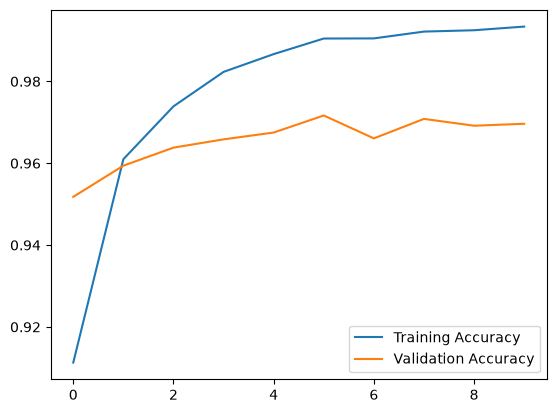

In [78]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

#### Model Preservation

In [79]:
model.save('prediction_model.keras')

#### Model Testing/Prediction Testing

In [80]:
test_data = pd.read_csv('./test.csv')
test_data

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5595,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5596,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5597,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5598,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [81]:
X_test = test_data.values / 255.0
X_test = X_test.reshape(-1, 28, 28, 1)

In [82]:
loaded_model = load_model('./prediction_model.keras')
predictions = loaded_model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)
predicted_labels

  1/175 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 733us/step


array([9, 1, 7, ..., 3, 9, 2], shape=(5600,))

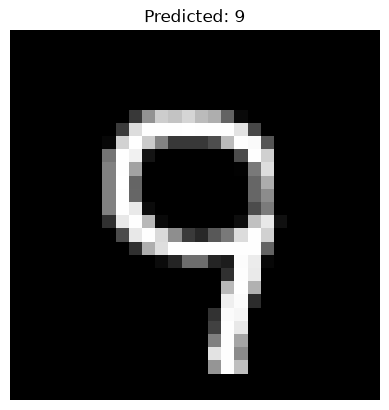

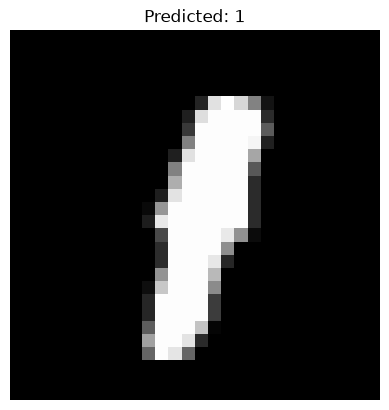

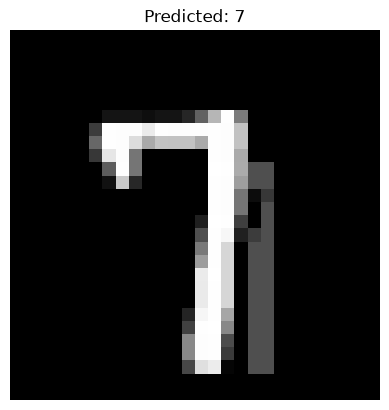

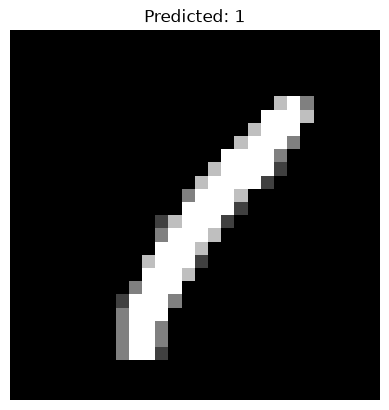

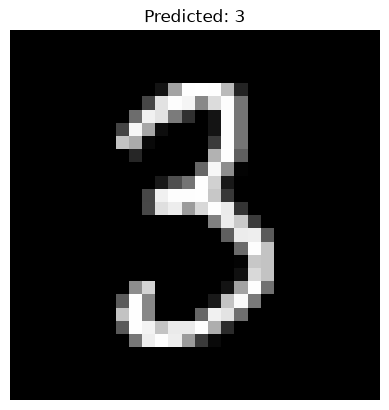

In [83]:
for i in range(5):
    plt.imshow(X_test[i].reshape(28,28), cmap='gray')
    plt.title(f"Predicted: {predicted_labels[i]}")
    plt.axis('off')
    plt.show()

In [84]:
test_loss, test_accuracy = loaded_model.evaluate(X_test, predictions)
print(f"Validation Accuracy: {test_accuracy * 100:.2f}%")

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 0.0335
Validation Accuracy: 100.00%
